# Листок 2
## Комплексные числа
Босарев Евгений Вадимович  
ЭФБО-11-24

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.special import loggamma
from IPython.display import display, Math

def show(label, value):
    display(Math(label+' = '+sp.latex(value)))

def plot_points(points, title):
    plt.figure(figsize=(5,5))
    plt.scatter(np.real(points),np.imag(points))
    for k,z in enumerate(points):
        plt.annotate(str(k), (z.real,z.imag),xytext=(4,4),
                     textcoords='offset points')
    plt.axhline(0,color='gray',lw=0.5)
    plt.axvline(0,color='gray',lw=0.5)
    plt.gca().set_aspect('equal',adjustable='box')
    plt.xlabel('Re z'); plt.ylabel('Im z'); plt.title(title)
    plt.grid(alpha=0.3); plt.show()


## 2.1
Каждый результат $z=x+iy$ переводится в формы $r(\cos\varphi+i\sin\varphi)$ и $re^{i\varphi}$, где $r=\sqrt{x^2+y^2}$, $\varphi=\operatorname{atan2}(y,x)$.

In [2]:
i=sp.I
values = [((5+i)*(7-6*i))/(3+i),
          (1+i)**5/(1-i)**3,
          (-1+i*sp.sqrt(3))**15/(1-i)**20
          +(-1-i*sp.sqrt(3))**15/(1+i)**20]
for label,z in zip('abc',values):
    z=sp.simplify(sp.expand_complex(z))
    r=sp.simplify(sp.Abs(z))
    phi=sp.arg(z)
    print(label)
    show('z',z); show('r',r); show(r'\varphi',phi)
    print('Тригонометрическая форма:',r,'*(cos(',phi,') + i*sin(',phi,'))')
    print('Показательная форма:',r,'*exp(i*(',phi,'))')


a


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Тригонометрическая форма: sqrt(221) *(cos( -atan(11/10) ) + i*sin( -atan(11/10) ))
Показательная форма: sqrt(221) *exp(i*( -atan(11/10) ))
b


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Тригонометрическая форма: 64 *(cos( pi ) + i*sin( pi ))
Показательная форма: 64 *exp(i*( pi ))


## 2.2
$1+i=\sqrt2e^{i\pi/4}$, поэтому
$$z_k=2^{1/16}\exp\left(i\left(\frac{\pi}{32}+\frac{\pi k}{4}\right)\right),\quad k=0,\ldots,7.$$
Точки лежат на окружности радиуса $2^{1/16}$ и образуют правильный восьмиугольник.

[ 1.03924532+0.10235673j  0.66248027+0.80723455j -0.10235673+1.03924532j
 -0.80723455+0.66248027j -1.03924532-0.10235673j -0.66248027-0.80723455j
  0.10235673-1.03924532j  0.80723455-0.66248027j]


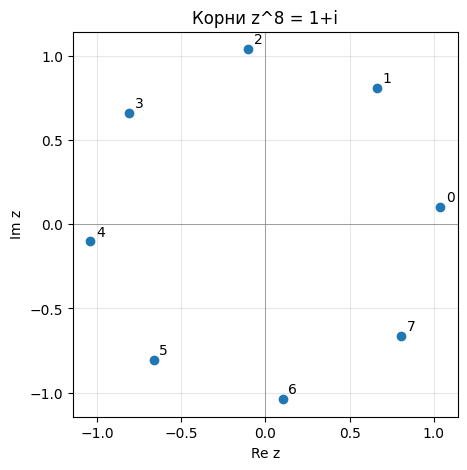

In [3]:
roots=2**(1/16)*np.exp(1j*(np.pi/32+np.arange(8)*np.pi/4))
print(roots)
assert np.allclose(roots**8,1+1j)
plot_points(roots,'Корни z^8 = 1+i')


## 2.3
Для $w=Re^{i\varphi}$ все корни степени $n$ имеют вид
$R^{1/n}e^{i(\varphi+2\pi k)/n}$, $k=0,\ldots,n-1$.

a подкоренное выражение: (1+0j) ; корни: [ 1.      +0.j        0.707107+0.707107j  0.      +1.j
 -0.707107+0.707107j -1.      +0.j       -0.707107-0.707107j
 -0.      -1.j        0.707107-0.707107j]


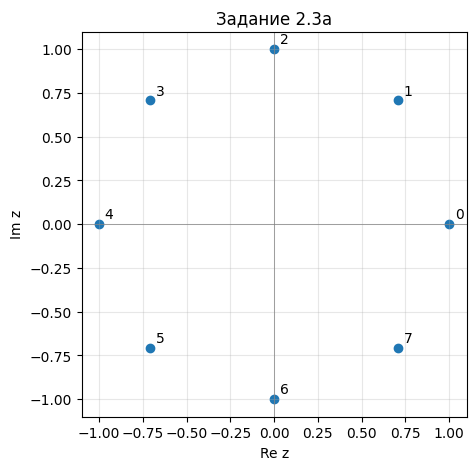

b подкоренное выражение: (-4.500000000000001+7.794228634059948j) ; корни: [ 1.5     +0.866025j -0.866025+1.5j      -1.5     -0.866025j
  0.866025-1.5j     ]


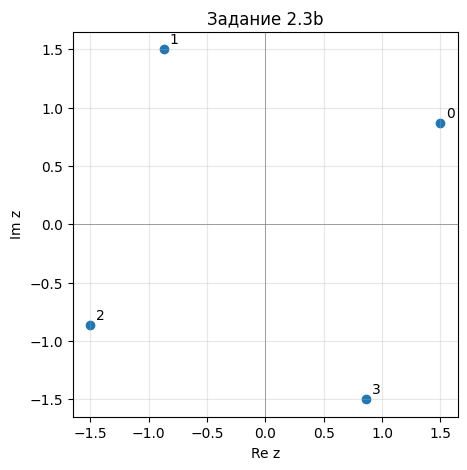

c подкоренное выражение: (9-8j) ; корни: [ 2.225163-0.549759j -0.636476+2.201928j -1.588687-1.652168j]


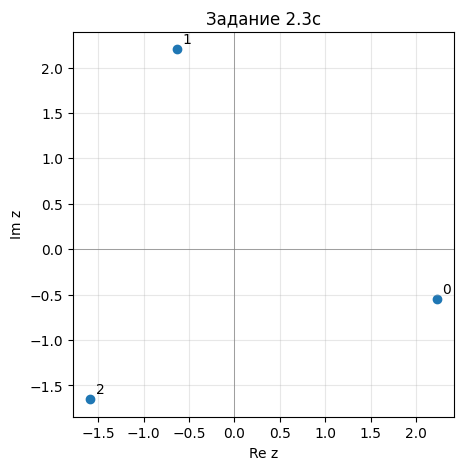

d подкоренное выражение: (1-1j) ; корни: [ 1.035305-0.090577j  0.851311+0.596095j  0.26898 +1.003847j
 -0.43921 +0.941889j -0.941889+0.43921j  -1.003847-0.26898j
 -0.596095-0.851311j  0.090577-1.035305j  0.734867-0.734867j]


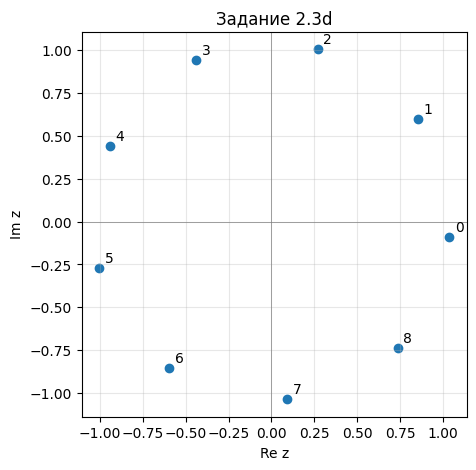

In [4]:
radicands=[(1+0j,8,'a'),
             (-18/(1+1j*np.sqrt(3)),4,'b'),
             ((1-5j)/(1+1j)-5*(1+2j)/(2-1j)+11,3,'c'),
             (1-1j,9,'d')]
for w,n,label in radicands:
    roots=abs(w)**(1/n)*np.exp(1j*(np.angle(w)+2*np.pi*np.arange(n))/n)
    print(label,'подкоренное выражение:',w,'; корни:',np.round(roots,6))
    assert np.allclose(roots**n,w)
    plot_points(roots,'Задание 2.3'+label)


## 2.4
Запишем $z=x+iy$.

а) $\sqrt{x^2+(y-1)^2}+\sqrt{x^2+(y+1)^2}<4$ — внутренность эллипса с фокусами $(0,1)$ и $(0,-1)$, большая полуось 2, малая $\sqrt3$.

б) $\operatorname{Re}(z(1-i))=x+y<\sqrt2$ — открытая полуплоскость.

в) Из $|z+i|=|z-i|$ следует $y=0$; затем $|z+1|=|z+i|$ даёт $x=0$. Ответ: $z=0$.

г–е) Для дробей исключаются точки, обращающие числитель или знаменатель в ноль: в них аргумент не определён. Области можно проверить непосредственно по неравенствам для главного аргумента. В пункте е) нижняя граница $-2\pi/3$ больше верхней $-5\pi/6$. При буквальном прочтении множество пусто — это показано на рисунке.

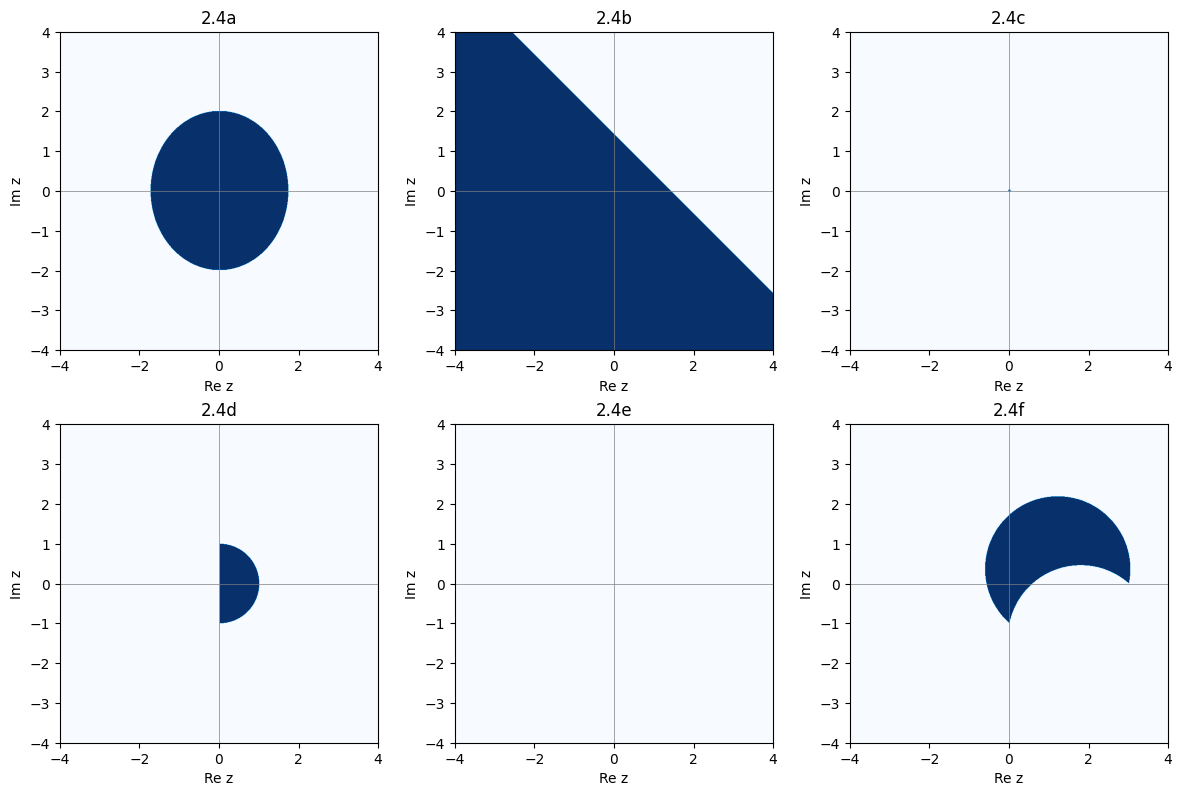

In [5]:
x=np.linspace(-4,4,701); y=np.linspace(-4,4,701)
X,Y=np.meshgrid(x,y); Z=X+1j*Y
def argument_region(numerator,denominator,low,high):
    with np.errstate(divide='ignore',invalid='ignore'):
        ratio=numerator/denominator
        angle=np.angle(ratio)
    valid=(abs(numerator)>1e-8)&(abs(denominator)>1e-8)
    return valid & (angle>=low) & (angle<=high)

regions=[
 ('a',np.sqrt(X**2+(Y-1)**2)+np.sqrt(X**2+(Y+1)**2)<4),
 ('b',X+Y<np.sqrt(2)),
 ('c',abs(Z)<0.03),
 ('d',argument_region(1j-Z,Z+1j,0,np.pi/2)
       & (np.angle((1j-Z)/(Z+1j))>0)
       & (np.angle((1j-Z)/(Z+1j))<np.pi/2)),
 ('e',argument_region(2-1j*Z,Z+3j,-2*np.pi/3,-5*np.pi/6)),
 ('f',argument_region(3-Z,Z+1j,-2*np.pi/3,-np.pi/3))]
fig,axes=plt.subplots(2,3,figsize=(12,8))
for ax,(label,mask) in zip(axes.flat,regions):
    ax.imshow(mask,origin='lower',extent=[-4,4,-4,4],cmap='Blues',vmin=0,vmax=1)
    ax.axhline(0,color='gray',lw=.5); ax.axvline(0,color='gray',lw=.5)
    ax.set(title='2.4'+label,xlabel='Re z',ylabel='Im z')
plt.tight_layout(); plt.show()


## 2.5
$$A|z|^2+\overline Bz+B\overline z+C
=A\left|z+\frac BA\right|^2+C-\frac{|B|^2}{A}.$$
Значит центр окружности $-B/A$, радиус $\sqrt{|B|^2-AC}/A$ при $A>0$. Условие $AC<|B|^2$ обеспечивает положительный радиус.

## 2.6
Все 11 корней находим численно; результат проверяем подстановкой в многочлен.

-1.7767690+0.0000000i
+1.0806017+0.3238931i
+1.0806017-0.3238931i
+0.4777545+0.9010752i
+0.4777545-0.9010752i
-0.0125002+1.1826991i
-0.0125002-1.1826991i
-0.4500371+0.8039231i
-0.4500371-0.8039231i
-0.7074345+0.4643747i
-0.7074345-0.4643747i
Сумма модулей: 11.973384469712109
Максимальная действительная часть: 1.0806017373578438


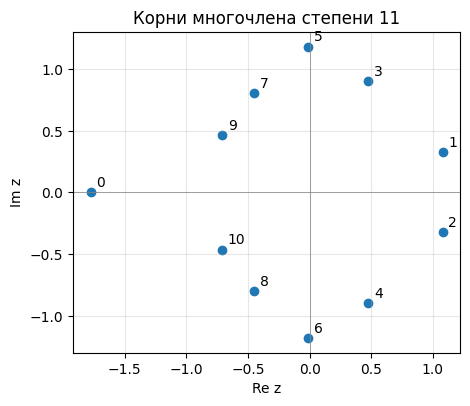

In [6]:
coefficients=[1,1,0,1,-2,0,-1,1,0,2,2,2]
roots=np.roots(coefficients)
for z in roots:
    print(f'{z.real:+.7f}{z.imag:+.7f}i')
print('Сумма модулей:',sum(abs(roots)))
print('Максимальная действительная часть:',max(roots.real))
assert np.max(abs(np.polyval(coefficients,roots)))<1e-5
plot_points(roots,'Корни многочлена степени 11')


## 2.7
Обобщённый биномиальный коэффициент выражается через гамма-функцию. В точках её полюсов выражение не определено. Линии уровня строятся по главному аргументу.

C = (4.36744914064015+4.8516297651578295j) ; Arg(C) = 0.8378693695500425 рад


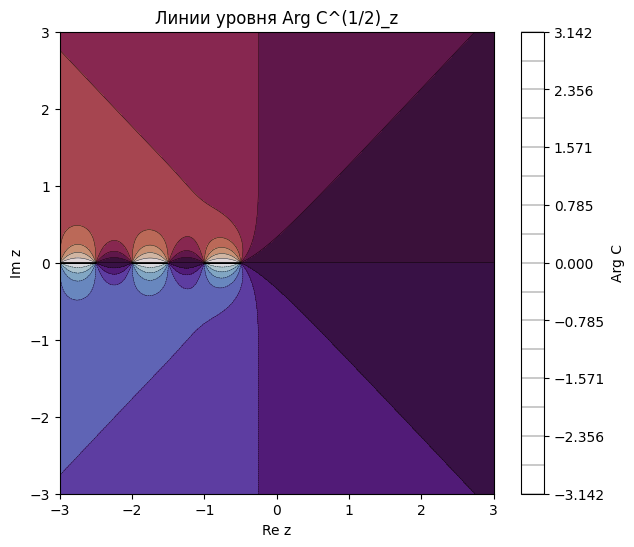

In [7]:
z=1+1j; w=1-1j
C=np.exp(loggamma(z+1)-loggamma(w+1)-loggamma(z-w+1))
print('C =',C,'; Arg(C) =',np.angle(C),'рад')
xx=np.linspace(-3,3,501); yy=np.linspace(-3,3,501)
XX,YY=np.meshgrid(xx,yy); ZZ=XX+1j*YY
with np.errstate(over='ignore',invalid='ignore',divide='ignore'):
    CC=np.exp(loggamma(ZZ+1)-loggamma(1.5)-loggamma(ZZ+0.5))
angle=np.angle(CC)
angle[~np.isfinite(CC)]=np.nan
plt.figure(figsize=(7,6))
plt.contourf(XX,YY,angle,levels=np.linspace(-np.pi,np.pi,17),cmap='twilight')
plt.contour(XX,YY,angle,levels=np.linspace(-np.pi,np.pi,17),colors='black',linewidths=.3)
plt.colorbar(label='Arg C'); plt.xlabel('Re z');plt.ylabel('Im z')
plt.title('Линии уровня Arg C^(1/2)_z');plt.show()


## 2.8
Из корней четырнадцатой степени выбираем $\lambda=e^{i\pi/7}$: среди корней с положительной мнимой частью он имеет наибольшую действительную часть. $\det(A+\lambda I)=\lambda^2+9\lambda-16$.

In [8]:
lam=np.exp(1j*np.pi/7)
det=lam**2+9*lam-16
print('lambda =',lam,'; Re det =',det.real,'; Im det =',det.imag)
assert np.allclose(det,np.linalg.det(np.array([[7,5],[6,2]])+lam*np.eye(2)))


lambda = (0.9009688679024191+0.4338837391175581j) ; Re det = -7.2677903870194935 ; Im det = 4.686785134526053


## 2.9
Строим приближённые множества Жюлиа методом обратных итераций. В каждой точке выбирается случайный обратный образ. Для квадратичного отображения $z^2+c$ это $z=\pm\sqrt{w-c}$; для двух рациональных отображений обратные формулы получаются из $w=f(z)$.

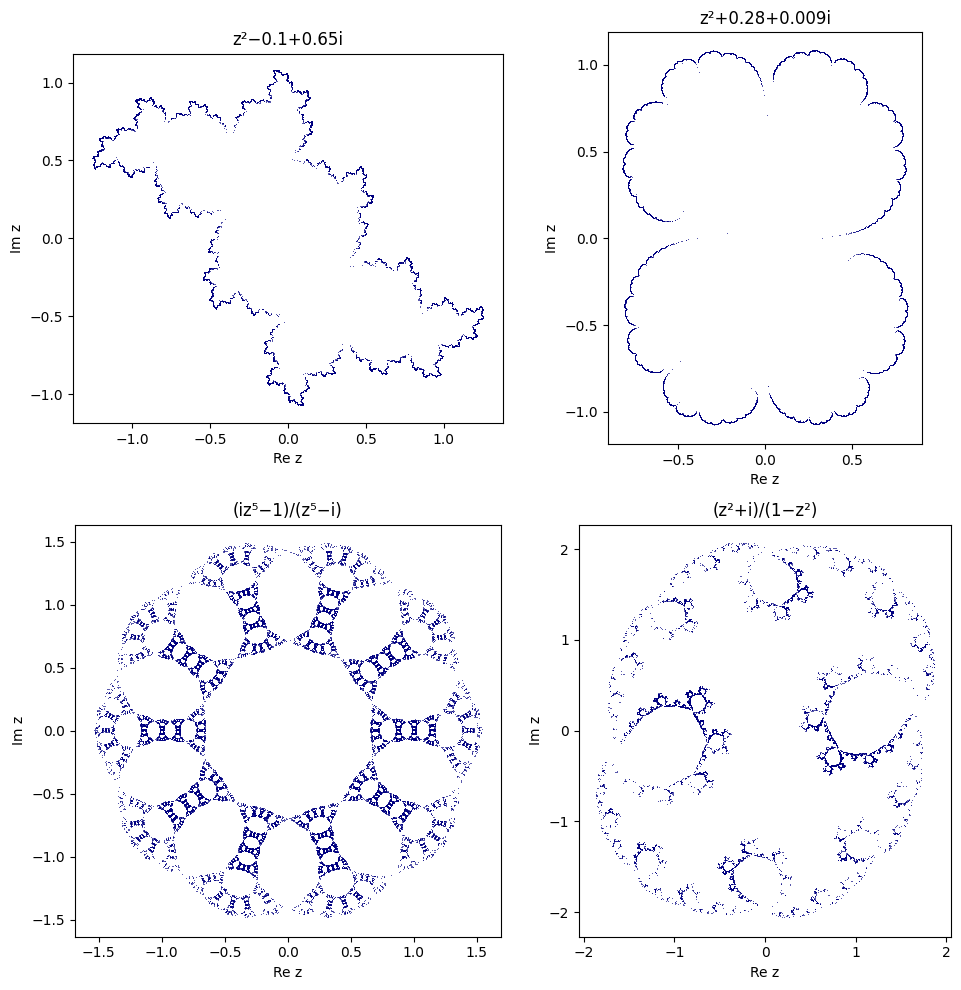

In [9]:
rng=np.random.default_rng(24)
def inverse_orbit(kind, count=60000):
    w=0.2+0.1j
    result=[]
    for step in range(count+100):
        if kind in ('c1','c2'):
            c=(-0.1+0.65j) if kind=='c1' else (0.28+0.009j)
            base=np.sqrt(w-c); n=2
        elif kind=='r1':
            base=((1j*w-1)/(w-1j))**(1/5); n=5
        else:
            base=np.sqrt((w-1j)/(w+1)); n=2
        k=rng.integers(n)
        w=base*np.exp(2j*np.pi*k/n)
        if step>=100:
            result.append(w)
    return np.array(result)

fig,axes=plt.subplots(2,2,figsize=(10,10))
for ax,kind,title in zip(axes.flat,['c1','c2','r1','r2'],
      ['z²−0.1+0.65i','z²+0.28+0.009i','(iz⁵−1)/(z⁵−i)',
       '(z²+i)/(1−z²)']):
    points=inverse_orbit(kind)
    ax.plot(points.real,points.imag,',',color='navy',alpha=.65)
    ax.set(title=title,xlabel='Re z',ylabel='Im z')
    ax.set_aspect('equal',adjustable='box')
plt.tight_layout();plt.show()


## 2.10
Используем обратную стереографическую проекцию $z=x+iy$:
$$X=\frac{2x}{1+x^2+y^2},\qquad Y=\frac{2y}{1+x^2+y^2},\qquad Z=\frac{x^2+y^2-1}{1+x^2+y^2}.$$
Подстановка даёт $X^2+Y^2+Z^2=1$. При росте $|z|$ точки приближаются к северному полюсу.

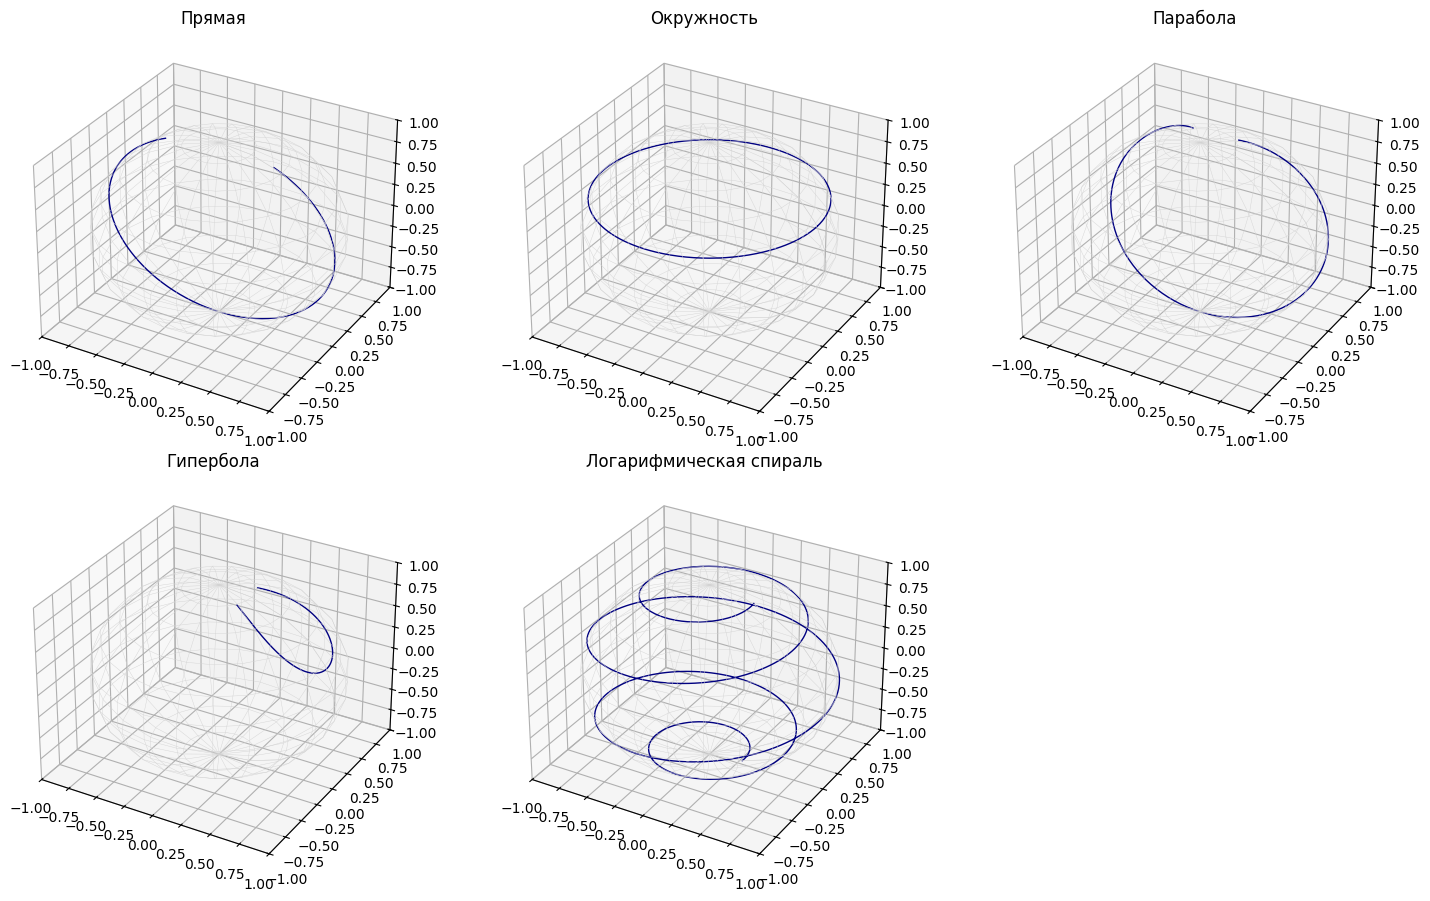

In [10]:
def sphere(z):
    x,y=np.real(z),np.imag(z)
    d=1+x*x+y*y
    return 2*x/d,2*y/d,(x*x+y*y-1)/d

t=np.linspace(-4,4,500)
theta=np.linspace(0,2*np.pi,500)
curves=[('Прямая',t+0j),('Окружность',1.5*np.exp(1j*theta)),
        ('Парабола',t+0.3j*t*t),('Гипербола',1.5*np.cosh(t/2)+1j*np.sinh(t/2)),
        ('Логарифмическая спираль',0.15*np.exp(0.14*theta*4)
         *np.exp(1j*theta*4))]
fig=plt.figure(figsize=(15,9))
u,v=np.mgrid[0:2*np.pi:24j,0:np.pi:12j]
for k,(name,z) in enumerate(curves,1):
    ax=fig.add_subplot(2,3,k,projection='3d')
    ax.plot_wireframe(np.cos(u)*np.sin(v),np.sin(u)*np.sin(v),np.cos(v),
                      color='lightgray',linewidth=.3)
    ax.plot(*sphere(z),color='navy',linewidth=1)
    ax.set(xlim=(-1,1),ylim=(-1,1),zlim=(-1,1),title=name)
plt.tight_layout();plt.show()
